In [1]:
#Purpose of this notebook: explore the fire/smoke dataset and check the label format.

In [2]:
%pip install numpy matplotlib pillow

  Using cached numpy-2.5.4-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached pillow-12.3.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (130 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached numpy-2.5.4-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (11.0 MB)
Using cached pillow-12.3.

In [ ]:
%pip install -q kagglehub

In [ ]:
import os
import kagglehub

DATA_DIR = kagglehub.dataset_download(
    "sayedgamal99/smoke-fire-detection-yolo"
    )
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("Train images:", len(os.listdir(os.path.join(TRAIN_DIR, "images"))))
print("Train labels:", len(os.listdir(os.path.join(TRAIN_DIR, "labels"))))
print("Test images:", len(os.listdir(os.path.join(TEST_DIR, "images"))))
print("Test labels:", len(os.listdir(os.path.join(TEST_DIR, "labels"))))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\louis\\Desktop\\NeuralNetworks\\Project/train/images'

In [ ]:
def read_labels(path):
    boxes = []
    with open(path, "r") as f:
        for line in f:
            parts = line.split()
            if len (parts) != 5:
                continue
            class_id, x_center, y_center, width, height = map(float, parts)
            class_id = int(class_id)
            boxes.append((class_id, x_center, y_center, width, height))
    return boxes

In [ ]:
fire_and_smoke_labels = read_labels(os.path.join(TEST_DIR, "labels", "PublicDataset01075.txt"))
empty = read_labels(os.path.join(TEST_DIR, "labels", "AoF06723.txt"))

print("Fire and smoke labels:", len(fire_and_smoke_labels), "boxes")
for box in fire_and_smoke_labels:
    print("Box:", box)

print("Empty labels:", len(empty), "boxes")


Fire and smoke labels: 3 boxes
Box: (1, 0.23981481481481481, 0.6152777777777778, 0.0462962962962963, 0.05277777777777778)
Box: (1, 0.4898148148148148, 0.6486111111111111, 0.04259259259259259, 0.04166666666666667)
Box: (0, 0.5166666666666667, 0.3680555555555556, 0.7481481481481482, 0.675)
Empty labels: 0 boxes


## 2. Annotation visualisation

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

CLASS_NAMES = ["smoke", "fire"]           
COLOURS = ["deepskyblue", "orangered"]     

def show_boxes(image_path, boxes, title=None):
    img = Image.open(image_path)          
    W, H = img.size                        

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(img)                         # show the image

    for class_id, x_center, y_center, width, height in boxes:
        
        box_w = width * W                  # box width in pixels
        box_h = height * H                 # box height in pixels

        # Labels give the CENTRE of the box, but matplotlib needs the TOP-LEFT corner,
        # so move half the box width left and half the box height up from the centre
        x0 = (x_center - width / 2) * W    
        y0 = (y_center - height / 2) * H   # top edge in pixels

        rect = patches.Rectangle((x0, y0), box_w, box_h,
                                 fill=False, linewidth=2,
                                 edgecolor=COLOURS[class_id])   # colour by class
        ax.add_patch(rect)                                      # draw the box
        ax.text(x0, y0 - 5, CLASS_NAMES[class_id],
                color=COLOURS[class_id], fontsize=10)           

    ax.set_title(title if title else os.path.basename(image_path))
    ax.axis("off")                         # hide the pixel axes
    plt.show()

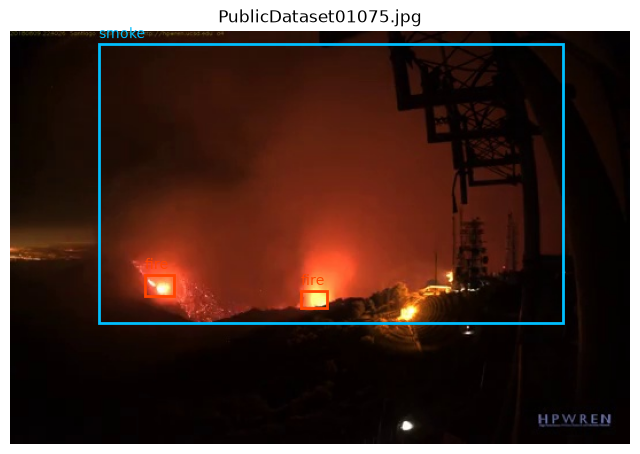

In [ ]:
image_path = os.path.join(TEST_DIR, "images", "PublicDataset01075.jpg")
show_boxes(image_path, fire_and_smoke_labels)

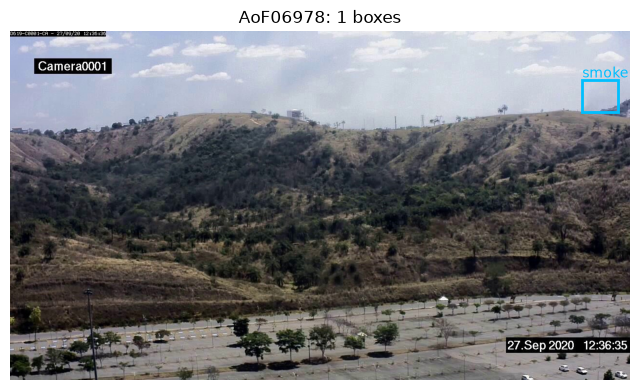

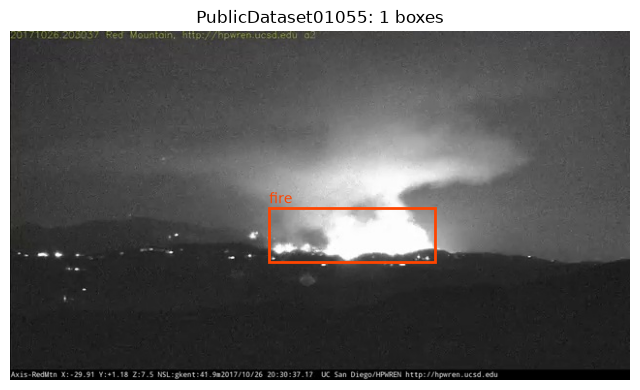

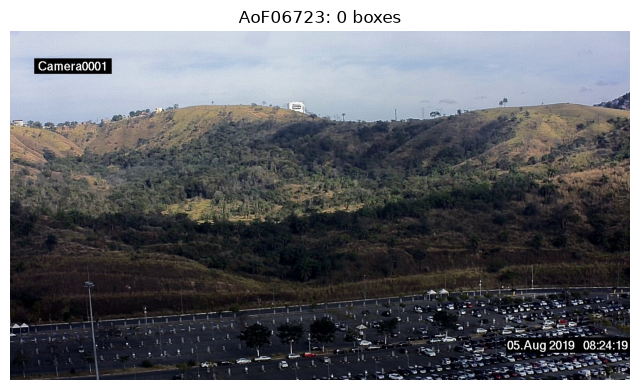

In [ ]:
for name in ["AoF06978", "PublicDataset01055", "AoF06723"]:
    labels = read_labels(os.path.join(TEST_DIR, "labels", name + ".txt"))
    show_boxes(os.path.join(TEST_DIR, "images", name + ".jpg"), labels,
               title=f"{name}: {len(labels)} boxes")

## 3. Exploratory Data Analysis (EDA)

In [ ]:
# Read every training label

def image_category(boxes):
    """Summarise an image as 'none', 'smoke', 'fire' or 'both' from its boxes."""
    classes = {box[0] for box in boxes}        # set of class ids present, e.g. {0, 1}
    if not classes:
        return "none"                          # no boxes at all
    if classes == {0}:
        return "smoke"
    if classes == {1}:
        return "fire"
    return "both"                              # contains 0 and 1

train_label_dir = os.path.join(TRAIN_DIR, "labels")
train_data = []                                # one entry per image
for filename in sorted(os.listdir(train_label_dir)):
    boxes = read_labels(os.path.join(train_label_dir, filename))
    train_data.append({"name": filename[:-4],   # filename without ".txt"
                       "boxes": boxes,
                       "category": image_category(boxes)})

print("Images loaded:", len(train_data))

Images loaded: 17221


  none:  7833 images (45.5%)
 smoke:  4681 images (27.2%)
  fire:   944 images (5.5%)
  both:  3763 images (21.9%)


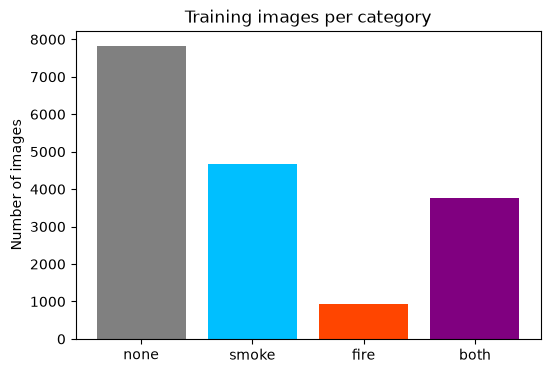

In [ ]:
# Class distribution in the training set

from collections import Counter

category_counts = Counter(item["category"] for item in train_data)
order = ["none", "smoke", "fire", "both"]
for cat in order:
    n = category_counts[cat]
    print(f"{cat:>6}: {n:>5} images ({100 * n / len(train_data):.1f}%)")

plt.figure(figsize=(6, 4))
plt.bar(order, [category_counts[c] for c in order],
        color=["grey", "deepskyblue", "orangered", "purple"])
plt.title("Training images per category")
plt.ylabel("Number of images")
plt.show()

Total boxes: 21364
Smoke boxes: 9550
Fire boxes: 11814


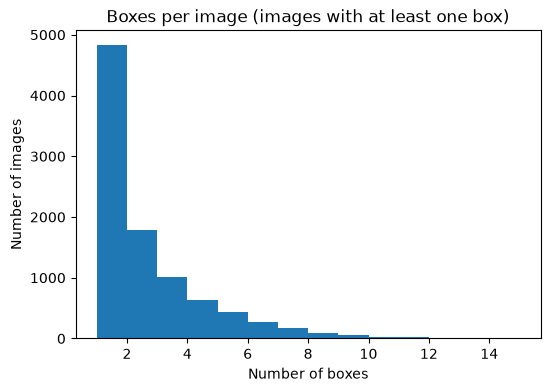

In [ ]:
# Objects per class, and boxes per image

box_counts = Counter(box [0] for item in train_data for box in item["boxes"])
print("Total boxes:", sum(box_counts.values()))
print("Smoke boxes:", box_counts[0])
print("Fire boxes:", box_counts[1])

boxes_per_image = [len(item["boxes"]) for item in train_data if item["boxes"]]
plt.figure(figsize = (6, 4))
plt.hist(boxes_per_image, bins=range(1, 16))
plt.title("Boxes per image (images with at least one box)")
plt.xlabel("Number of boxes")
plt.ylabel("Number of images")
plt.show()

smoke: median size 0.377, 7.8% are tiny (< 5% of image side)
fire: median size 0.073, 33.2% are tiny (< 5% of image side)


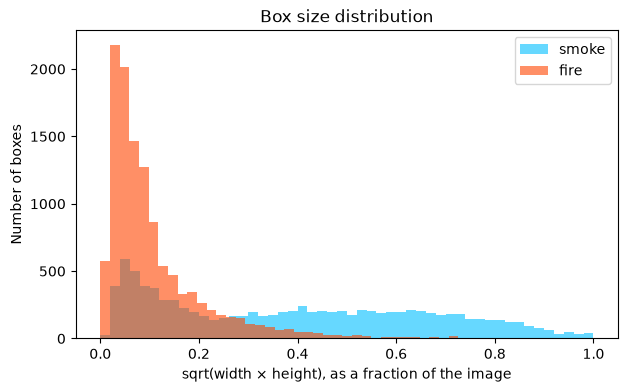

In [ ]:
# Box Sizes
import numpy as np

plt.figure(figsize=(7, 4))
for class_id in [0, 1]:
    # sqrt(width * height) = a box's 'size' as a fraction of the image side
    sizes = [np.sqrt(b[3] * b[4]) for item in train_data for b in item["boxes"] if b[0] == class_id]
    plt.hist(sizes, bins=50, alpha=0.6, color=COLOURS[class_id], label=CLASS_NAMES[class_id])
    small = np.mean(np.array(sizes) < 0.05) * 100
    print(f"{CLASS_NAMES[class_id]}: median size {np.median(sizes):.3f}, {small:.1f}% are tiny (< 5% of image side)")

plt.title("Box size distribution")
plt.xlabel("sqrt(width × height), as a fraction of the image")
plt.ylabel("Number of boxes")
plt.legend()
plt.show()

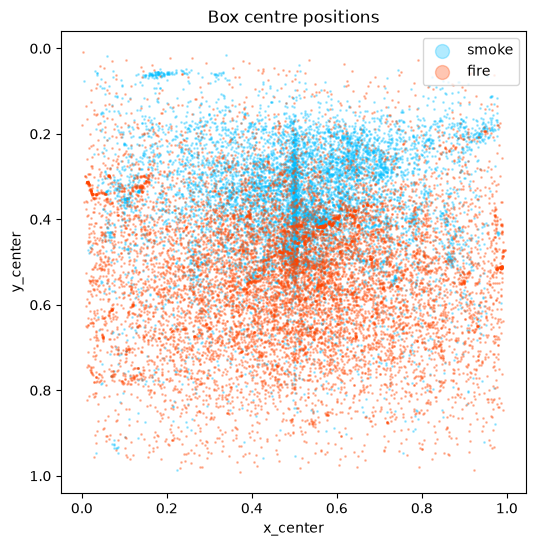

In [ ]:
# Where objects appeear in the image

plt.figure(figsize=(6, 6))
for class_id in [0, 1]:
    xs = [b[1] for item in train_data for b in item["boxes"] if b[0] == class_id]
    ys = [b[2] for item in train_data for b in item["boxes"] if b[0] == class_id]
    plt.scatter(xs, ys, s=1, alpha=0.3, color=COLOURS[class_id], label=CLASS_NAMES[class_id])

plt.gca().invert_yaxis()                       # images have y=0 at the top
plt.title("Box centre positions")
plt.xlabel("x_center")
plt.ylabel("y_center")
plt.legend(markerscale=10)
plt.show()